# Bank Customer Segmentation and Credit Risk: Part 2, Time Series

In this notebook I look at how the bank's customers behaved over the six years from 1993 to 1998: how the bank grew, how active customers were, whether there are regular patterns during the year or the month, how balances developed, and whether financial stress increased.

It starts from the clean tables saved in `01_data_preparation.ipynb`, so that notebook has to be run first.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

## Loading the clean data

Three of the saved tables are needed here:
- `trans`: every transaction
- `daily_balance`: one end-of-day balance per account and day (built in notebook 01, because the order of transactions within a day is unreliable)
- `account_profile`: one row per account

In [20]:
trans = pd.read_parquet("data/clean/trans.parquet")
daily_balance = pd.read_parquet("data/clean/daily_balance.parquet")
account_profile = pd.read_parquet("data/clean/account_profile.parquet")

print(f"trans:           {len(trans):,} rows")
print(f"daily_balance:   {len(daily_balance):,} rows")
print(f"account_profile: {len(account_profile):,} rows")

trans:           1,056,320 rows
daily_balance:   814,768 rows
account_profile: 4,500 rows


Because these were saved as Parquet, the column types are kept: the dates are still dates, without converting them again.

In [21]:
trans.dtypes

trans_id                  int64
account_id                int64
date             datetime64[us]
direction                   str
operation                   str
amount                  float64
balance                 float64
purpose                     str
bank                        str
account                 float64
signed_amount           float64
dtype: object

### Customer-initiated transactions only

Some transactions are created by the bank itself, not by the customer: interest, statement fees and penalty interest. They happen automatically every month, so they say nothing about how customers behave. For analysing activity, I keep only the transactions a customer made.

Balances are different: they include everything, so for balances I will use `daily_balance`, which already accounts for all transactions.

In [22]:
bank_generated = ["interest credited", "statement fee", "penalty interest"]
customer_trans = trans[~trans["purpose"].isin(bank_generated)].copy()

print(f"all transactions:      {len(trans):,}")
print(f"created by the bank:   {len(trans) - len(customer_trans):,}")
print(f"made by customers:     {len(customer_trans):,}")

all transactions:      1,056,320
created by the bank:   340,523
made by customers:     715,797


In [23]:
# check what was removed
trans.loc[trans["purpose"].isin(bank_generated), "purpose"].value_counts()

purpose
interest credited    183114
statement fee        155832
penalty interest       1577
Name: count, dtype: int64

About a third of all transactions (340,523) were created by the bank. Leaving them in would make every customer look much more active than they really are, and would add an artificial month-end peak, because interest and fees are booked on the last day of each month.

715,797 customer transactions remain for the activity analysis.

## How did the bank grow?

First, the big picture: how many accounts were active each month, and how many transactions they made. An account counts as **active** in a month if it made at least one transaction that month.

To group by month, I turn each date into a monthly period with `.dt.to_period("M")`, so 1995-08-21 and 1995-08-31 both become `1995-08`.

In [24]:
customer_trans["month"] = customer_trans["date"].dt.to_period("M")

monthly = customer_trans.groupby("month").agg(
    active_accounts=("account_id", "nunique"),
    transactions=("trans_id", "count"),
    total_amount=("amount", "sum"),
)
monthly.head()

,active_accounts,transactions,total_amount
month,,,
1993-01,96,140,700938.0
1993-02,194,290,2720895.0
1993-03,298,489,4714827.0
1993-04,375,641,7351072.0
1993-05,466,916,11638154.0


For comparison, I also count how many accounts **existed** at the end of each month: the running total of accounts opened so far.

In [25]:
opened_per_month = account_profile["opened"].dt.to_period("M").value_counts().sort_index()
monthly["existing_accounts"] = opened_per_month.reindex(monthly.index, fill_value=0).cumsum()

monthly.loc[["1993-01", "1993-12", "1995-12", "1997-12", "1998-12"]]

,active_accounts,transactions,total_amount,existing_accounts
month,,,,
1993-01,96,140,700938.0,96
1993-12,1138,3956,40050363.0,1139
1995-12,2236,9612,86526712.1,2239
1997-12,4476,19710,182518003.8,4500
1998-12,4424,19052,170892051.6,4500


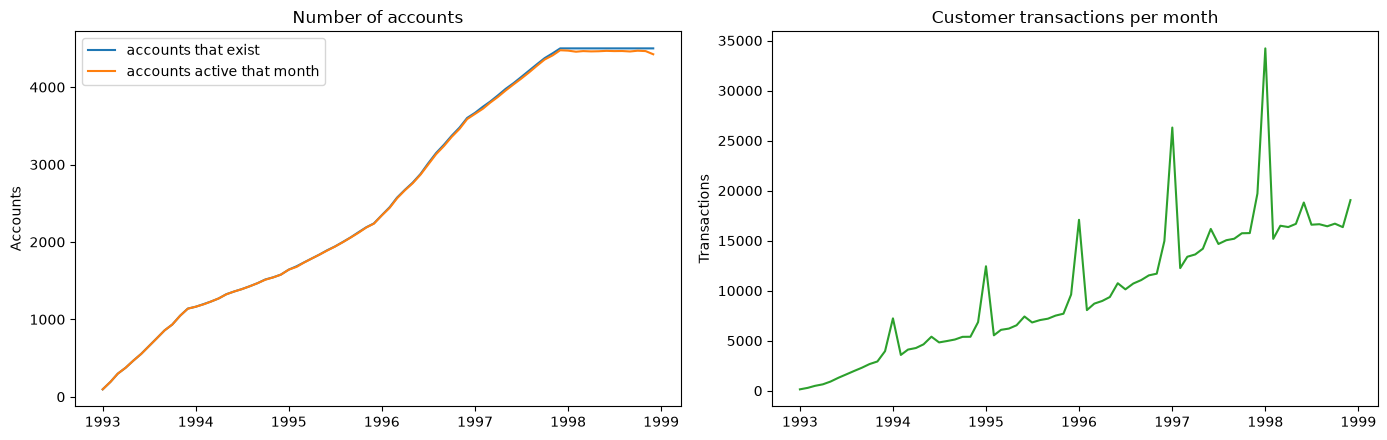

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

x = monthly.index.to_timestamp()

ax1.plot(x, monthly["existing_accounts"], label="accounts that exist")
ax1.plot(x, monthly["active_accounts"], label="accounts active that month")
ax1.set_title("Number of accounts")
ax1.set_ylabel("Accounts")
ax1.legend()

ax2.plot(x, monthly["transactions"], color="tab:green")
ax2.set_title("Customer transactions per month")
ax2.set_ylabel("Transactions")

plt.tight_layout()
plt.show()

- The bank grew from **96 active accounts** in January 1993 to **4,476** in December 1997. No new accounts were opened in 1998, so the number of accounts levels off.
- Almost every existing account is active every month. The two lines are nearly on top of each other, which fits the finding that this dataset only contains accounts that stayed open.
- Monthly transactions rise from **140** to about **19,000–20,000**, and the curve has the same shape as the account curve.
- There are clear spikes in the transaction chart once a year. I will look at those in the seasonality section.

**The key point:** total transactions rise mainly because the bank gained customers. Totals like these are useful for describing the bank, but they can't tell me whether customers became more or less active. For that I need activity **per account**, which is the next section.

## Activity per customer

To see whether customers themselves changed, I divide by the number of active accounts. This **normalising** turns totals into rates that can be compared across the six years:
- **transactions per active account**: how often a typical account is used each month
- **average transaction amount**: how large a typical transaction is
- **amount per active account**: how much money moves through a typical account each month

In [27]:
monthly["trans_per_account"] = monthly["transactions"] / monthly["active_accounts"]
monthly["avg_amount"] = monthly["total_amount"] / monthly["transactions"]
monthly["amount_per_account"] = monthly["total_amount"] / monthly["active_accounts"]

monthly[["trans_per_account", "avg_amount", "amount_per_account"]].describe().round(1)

,trans_per_account,avg_amount,amount_per_account
count,72.0,72.0,72.0
mean,3.6,9056.5,31983.0
std,1.2,1483.4,6503.8
min,1.5,5006.7,7301.4
25%,3.4,8746.6,30049.0
50%,3.5,8981.1,31384.5
75%,3.7,9211.7,33438.6
max,7.7,14067.5,46798.5


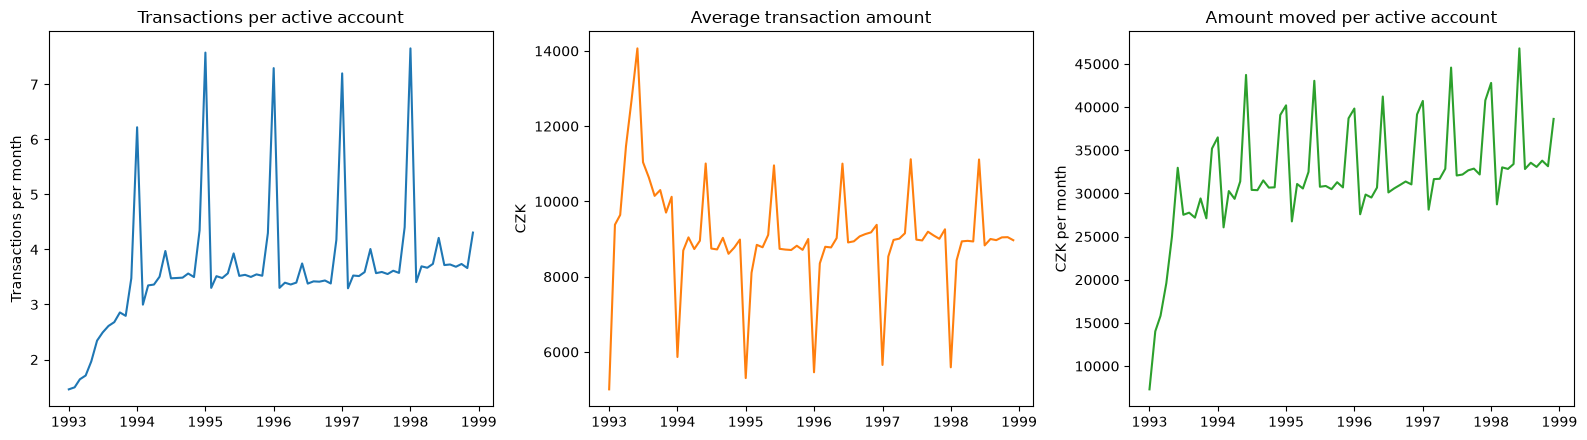

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = monthly.index.to_timestamp()

axes[0].plot(x, monthly["trans_per_account"])
axes[0].set_title("Transactions per active account")
axes[0].set_ylabel("Transactions per month")

axes[1].plot(x, monthly["avg_amount"], color="tab:orange")
axes[1].set_title("Average transaction amount")
axes[1].set_ylabel("CZK")

axes[2].plot(x, monthly["amount_per_account"], color="tab:green")
axes[2].set_title("Amount moved per active account")
axes[2].set_ylabel("CZK per month")

plt.tight_layout()
plt.show()

The first months of 1993 look different, because almost every account was brand new. A new account usually starts with one deposit, so it has few transactions in its first month. To compare the years fairly, I look at yearly averages from 1994 on, leaving out January (which has the spike) so it doesn't distort the comparison.

In [29]:
by_year = monthly.copy()
by_year["year"] = by_year.index.year
by_year = by_year[(by_year["year"] >= 1994) & (by_year.index.month != 1)]

by_year.groupby("year")[["trans_per_account", "avg_amount", "amount_per_account"]].mean().round(1)

,trans_per_account,avg_amount,amount_per_account
year,,,
1994,3.5,9028.8,32141.9
1995,3.6,8955.5,32431.6
1996,3.5,9142.8,32008.6
1997,3.7,9209.9,33787.6
1998,3.8,9113.5,34525.8


- After the start-up year of 1993, a typical account makes about **3.5–3.8 transactions a month** (outside January). That rises only very slightly from 1994 to 1998, so customers did not become much more active over time.
- The **average transaction amount** stays at about 9,000–9,200 CZK every year. So the large rise in total money moving through the bank (seen in Task 2.2) came almost entirely from having more customers, not from customers moving more money each.
- In 1993 the average amount is unusually high: most accounts were new, and an account's first transactions are often a large opening deposit.

The charts also show patterns that repeat **every year**:
- **January:** each account makes about twice as many transactions as usual, but they are much smaller (about 5,600 CZK on average instead of about 9,000). The spike is still there after normalising, so it isn't caused by growth.
- **June:** a peak in amounts but not in the number of transactions: the average transaction is about 11,000 CZK, and the money moved per account is the highest of the year.
- **December:** a smaller rise in both.

These yearly patterns are what the next section, on seasonality, looks at.

## Seasonality: patterns that repeat every year

The charts above show the same shape every year. To measure it, I average each **calendar month** (all Januaries together, all Februaries together, and so on) over 1994–1998, leaving out the start-up year 1993.

In [30]:
steady = monthly[monthly.index.year >= 1994].copy()
steady["calendar_month"] = steady.index.month

by_month = steady.groupby("calendar_month")[["trans_per_account", "avg_amount", "amount_per_account"]].mean()
by_month.round(1)

,trans_per_account,avg_amount,amount_per_account
calendar_month,,,
1,7.2,5575.9,40006.4
2,3.3,8424.6,27449.5
3,3.5,8920.7,31179.9
4,3.5,8851.9,30797.0
5,3.6,9036.9,32161.5
6,4.0,11041.5,43872.5
7,3.5,8843.3,31235.8
8,3.6,8870.4,31509.9
9,3.5,8996.2,31742.2


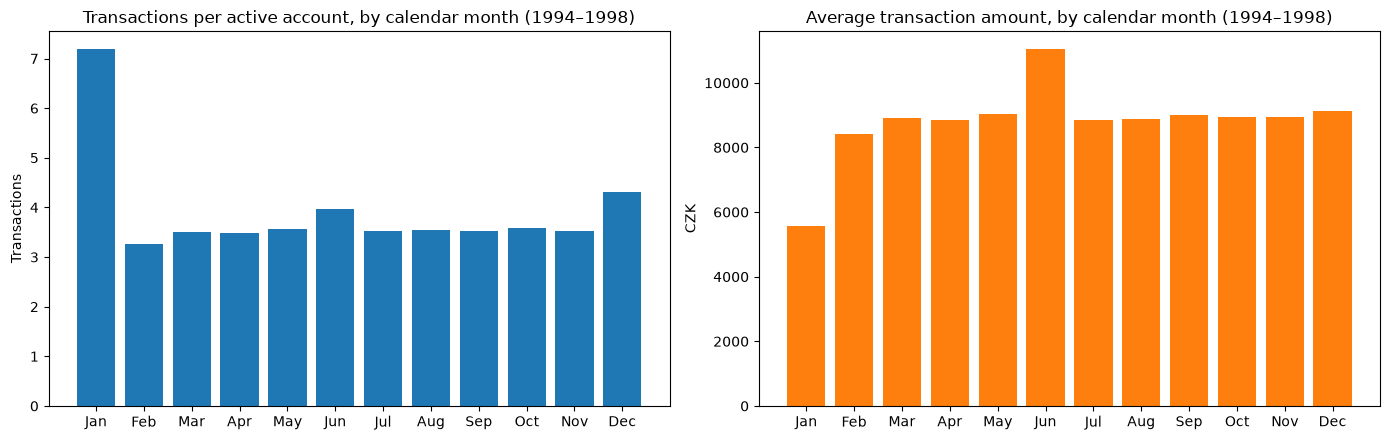

In [31]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.bar(month_names, by_month["trans_per_account"])
ax1.set_title("Transactions per active account, by calendar month (1994–1998)")
ax1.set_ylabel("Transactions")

ax2.bar(month_names, by_month["avg_amount"], color="tab:orange")
ax2.set_title("Average transaction amount, by calendar month (1994–1998)")
ax2.set_ylabel("CZK")

plt.tight_layout()
plt.show()

January stands out: about **twice the usual number of transactions**, but at **less than two thirds the usual size**. June has normal activity but larger transactions. December is a little above normal in both.

### Which transactions cause it?

I compare each type of transaction in January (and June) with a **normal month**, meaning the average of February–May and July–November. A ratio of 1 means "same as normal", 2 means "twice as many".

In [32]:
seasonal = customer_trans[customer_trans["date"].dt.year >= 1994].copy()
seasonal["calendar_month"] = seasonal["date"].dt.month
seasonal["kind"] = seasonal["operation"] + " / " + seasonal["purpose"]

normal_months = [2, 3, 4, 5, 7, 8, 9, 10, 11]

counts = pd.crosstab(seasonal["kind"], seasonal["calendar_month"])
amounts = pd.crosstab(seasonal["kind"], seasonal["calendar_month"], values=seasonal["amount"], aggfunc="mean")

comparison = pd.DataFrame({
    "total transactions": counts.sum(axis=1),
    "January count vs normal": counts[1] / counts[normal_months].mean(axis=1),
    "June avg amount vs normal": amounts[6] / amounts[normal_months].mean(axis=1),
})
comparison.sort_values("total transactions", ascending=False).round(2)

,total transactions,January count vs normal,June avg amount vs normal
kind,,,
cash withdrawal / none,267910,3.72,1.25
cash deposit / none,150058,0.96,1.25
transfer out / household bills,113419,0.86,1.00
transfer out / none,59959,0.86,1.00
transfer in / none,33575,0.89,1.45
transfer in / pension,29189,0.91,1.00
transfer out / insurance,18134,0.87,0.98
transfer out / loan repayment,13540,0.81,1.00
card withdrawal / none,8036,8.27,1.03


- Almost every type of transaction is **normal or slightly lower** in January (ratios around 0.8–1.0).
- Two types explain the whole spike: **cash withdrawals** (about **3.7×** the normal count) and **card withdrawals** (about **8×**).
- June is different. The **regular payments** (household bills, pensions, loan repayments, insurance) are exactly normal. What is larger is the **irregular money coming in**: transfers in without a fixed purpose are about **1.45×** their normal size and cash deposits about **1.25×**. Cash withdrawals are also about 1.25× larger. Extra income in June, such as a mid-year bonus, followed by larger spending, would look like this, so the June pattern is plausible as real behaviour.

### A closer look at January cash withdrawals

In [33]:
cash = seasonal[seasonal["kind"] == "cash withdrawal / none"]

print("Amount of a cash withdrawal (CZK):")
print(cash.groupby(cash["calendar_month"] == 1)["amount"].median().rename({False: "other months, median", True: "January, median"}))

Amount of a cash withdrawal (CZK):
calendar_month
other months, median    5700.0
January, median         2240.0
Name: amount, dtype: float64


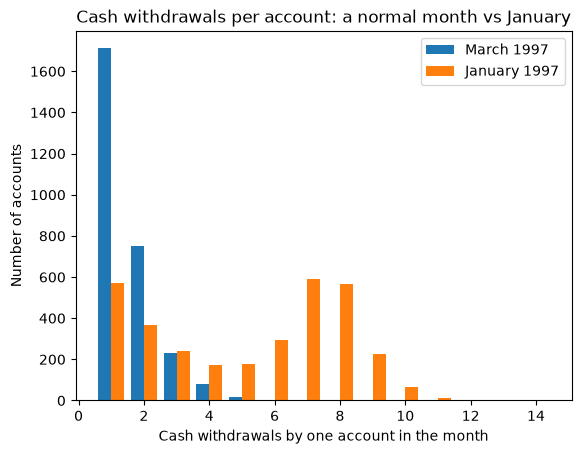

In [34]:
# cash withdrawals per account in January 1997 compared with a normal month, March 1997
jan = cash[(cash["date"].dt.year == 1997) & (cash["calendar_month"] == 1)].groupby("account_id").size()
mar = cash[(cash["date"].dt.year == 1997) & (cash["calendar_month"] == 3)].groupby("account_id").size()

bins = range(1, 16)
plt.hist([mar, jan], bins=bins, label=["March 1997", "January 1997"], align="left")
plt.xlabel("Cash withdrawals by one account in the month")
plt.ylabel("Number of accounts")
plt.title("Cash withdrawals per account: a normal month vs January")
plt.legend()
plt.show()

In [35]:
# are the extra January withdrawals concentrated on particular days?
jan_cash = cash[cash["calendar_month"] == 1]
days = jan_cash["date"].dt.day.value_counts().sort_index()
print("busiest day:", days.max(), " quietest day (1st–30th):", days.loc[1:30].min())

busiest day: 2261  quietest day (1st–30th): 1789


What the evidence shows:
- In a normal month, most accounts make **1 or 2** cash withdrawals. In January, a large group of accounts makes **6–8**, a clear second peak that doesn't exist in any other month.
- The January withdrawals are **small**: the median is about 2,200 CZK, against about 5,700 CZK in other months.
- They are spread **evenly across the whole of January**, not bunched around particular days.
- The pattern has **the same size every year**, from 1994 to 1998.

### Real behaviour or an artifact?

**For real behaviour:** people do spend more around the holidays, and New Year sales could mean extra cash withdrawals.

**Against:**
- Holiday spending would normally peak in **December**, not January.
- In real data, a seasonal effect usually raises activity gradually across many customers. Here, one group of accounts suddenly jumps from 1–2 withdrawals to exactly 6–8, and only in January.
- An effect this large that is the same size every year, for one transaction type, looks like the output of a rule rather than people.

**My conclusion:** this looks more like an **artifact** of how the data was prepared (for example while anonymising or extending it) than real customer behaviour. I can't prove it, so I treat it as a **known quirk** of the dataset, and **I will leave out January** when building customer behaviour features for segmentation, so that this pattern doesn't drive the clusters.

### Trend, seasonality and noise

Finally, `seasonal_decompose` from statsmodels splits the monthly series of transactions per account into three parts:
- **trend:** the slow, long-term movement
- **seasonal:** the pattern that repeats every 12 months
- **residual:** what is left over (noise)

(statsmodels needs to be installed: `pip install statsmodels`.)

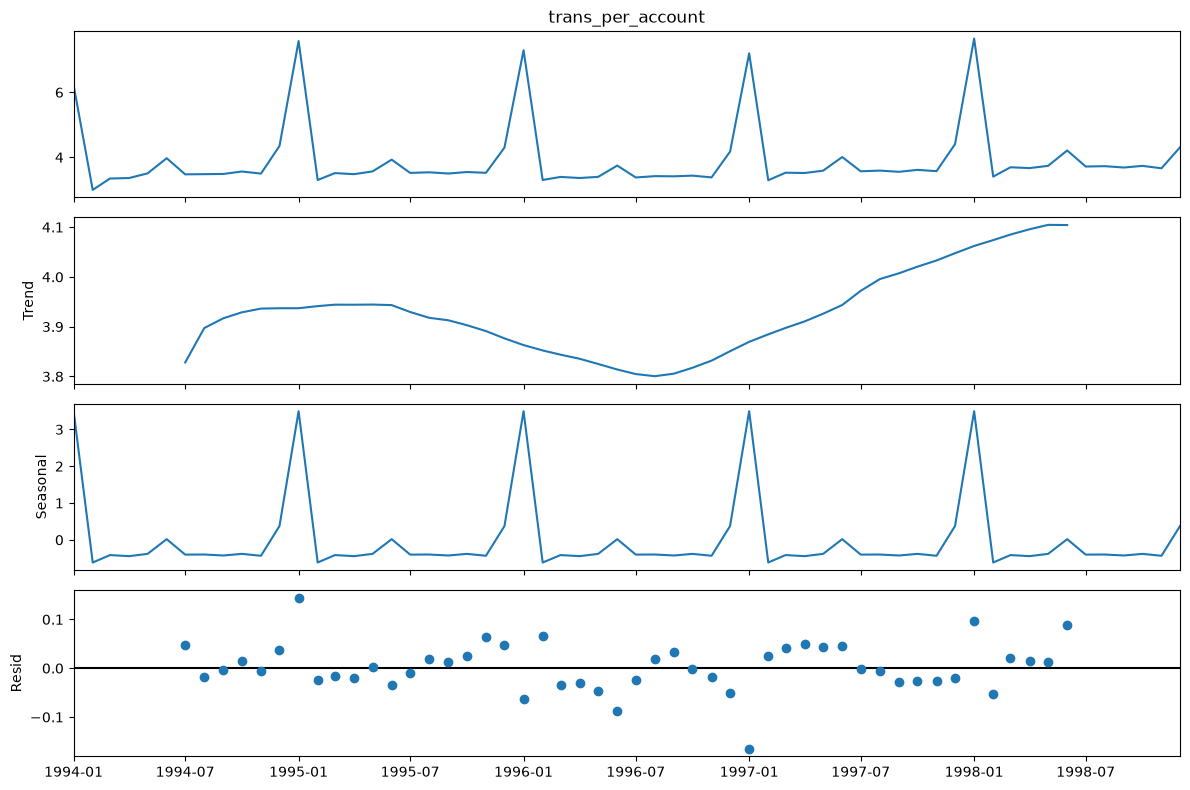

In [36]:
from statsmodels.tsa.seasonal import seasonal_decompose

series = steady["trans_per_account"]
series.index = series.index.to_timestamp()

decomposition = seasonal_decompose(series, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

- **Trend:** almost flat. It stays between about 3.8 and 4.1 transactions per account per month: a slight dip in 1996 and a slight rise in 1997–1998. Customers' activity barely changed over the five years.
- **Seasonal:** dominated by January, about **+3.5** transactions above the trend. December is about +0.4 and June about 0; every other month is about 0.4 below the trend. Those small negatives are the January spike being balanced out, because the seasonal part has to average to zero over the year.
- **Residual:** small for every month (at most 0.17), so trend and seasonality together explain this series almost completely.

This confirms the earlier findings in one chart: no real change in activity over time, and one very strong yearly January effect.

## When in the month do customers transact?

Next, the pattern **within** a month: how activity is spread across the days 1 to 31. I use 1994–1998 and leave out January, so that neither the start-up year nor the January artifact affects the result.

Not every month has a 29th, 30th or 31st, so raw counts would make those days look quiet for no real reason. To compare days fairly, I divide by the number of dates each day-of-month actually appeared on: the **average number of transactions on that day**.

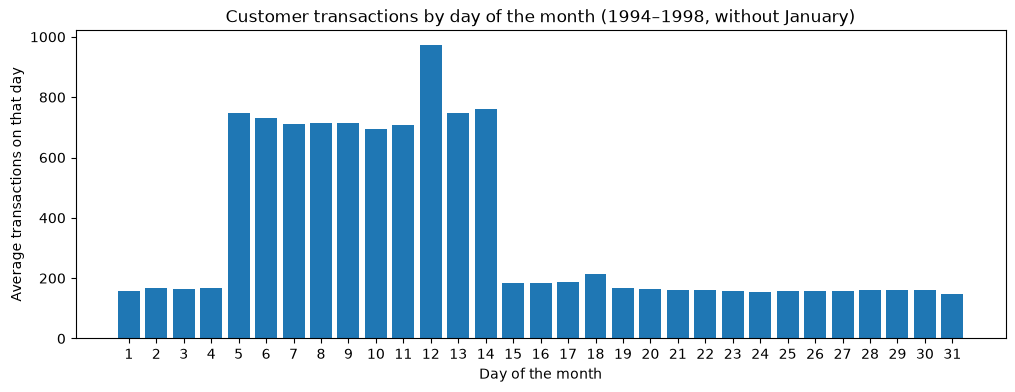

In [37]:
monthly_pattern = customer_trans[(customer_trans["date"].dt.year >= 1994) &
                                 (customer_trans["date"].dt.month != 1)].copy()
monthly_pattern["day"] = monthly_pattern["date"].dt.day
monthly_pattern["kind"] = monthly_pattern["operation"] + " / " + monthly_pattern["purpose"]

per_day = monthly_pattern.groupby("day").agg(transactions=("trans_id", "count"),
                                             dates=("date", "nunique"))
per_day["avg_per_date"] = per_day["transactions"] / per_day["dates"]

plt.figure(figsize=(12, 4))
plt.bar(per_day.index, per_day["avg_per_date"])
plt.xticks(range(1, 32))
plt.xlabel("Day of the month")
plt.ylabel("Average transactions on that day")
plt.title("Customer transactions by day of the month (1994–1998, without January)")
plt.show()

The month splits into two very different parts: days **5 to 14** have about four times as many transactions as the rest of the month, with a further peak on the **12th**. After adjusting for how often each day occurs, the 31st looks like any other quiet day.

### Which transactions happen when?

I split the month into three periods and check what share of each transaction type falls into each.

In [38]:
monthly_pattern["period"] = pd.cut(monthly_pattern["day"], bins=[0, 4, 14, 31],
                                   labels=["days 1-4", "days 5-14", "days 15-31"])

timing = pd.crosstab(monthly_pattern["kind"], monthly_pattern["period"], normalize="index")
timing["transactions"] = monthly_pattern["kind"].value_counts()
timing.sort_values("days 5-14").round(2)

period,days 1-4,days 5-14,days 15-31,transactions
kind,,,,
cash withdrawal / insurance,0.36,0.32,0.32,22
card withdrawal / none,0.13,0.32,0.55,5071
cash withdrawal / none,0.13,0.34,0.53,205243
cash withdrawal / household bills,0.18,0.50,0.32,2528
cash deposit / none,0.06,0.66,0.28,137997
transfer in / none,0.00,1.00,0.00,31071
transfer in / pension,0.00,1.00,0.00,26984
transfer out / household bills,0.00,1.00,0.00,105302
transfer out / insurance,0.00,1.00,0.00,16823


In [39]:
# on which days are loan repayments made?
monthly_pattern.loc[monthly_pattern["purpose"] == "loan repayment", "day"].value_counts()

day
12    12619
Name: count, dtype: int64

This is a very clear split:
- **Every single transfer**, in or out, happens between the 5th and the 14th. That includes household bills, insurance, pensions, other incoming money and other outgoing transfers: not one of them on any other day in five years.
- **Every loan repayment** is made on the **12th**, which explains the peak on that day.
- **Cash withdrawals and card withdrawals** are spread evenly over the whole month: only about a third fall on days 5–14, which is what you would expect if they were spread at random (10 of 31 days).
- **Cash deposits** are in between: about two thirds happen on days 5–14, so many customers deposit cash around the same time as their regular income arrives.

### What this means

Some of this is realistic. Banks do process standing orders and loan repayments on fixed dates, and pensions and salaries usually arrive on the same days each month. Customers withdrawing cash whenever they need it, spread over the month, is also natural.

But **no transfer at all outside days 5–14**, for every customer over five years, is stricter than real banking data would be. People also send and receive one-off transfers on other days. Like the January pattern, this looks like the regular payments were placed on dates by a rule when the data was prepared.

**Decision for later steps:** the day of the month carries almost no information about individual customers here, because everyone's transfers follow the same schedule. So I won't use timing within the month as a customer feature. What still differs between customers is **what kinds** of transactions they make and **how much** money they move, and those are what I will use for segmentation.

## Balances over time

So far I have looked at transactions. Now the money that stays in the accounts: how large are balances, and how did they change?

### An end-of-month balance for every account

I use `daily_balance` from notebook 01, which has one reliable end-of-day balance per account per day. Unlike the activity analysis, this includes **all** transactions, interest and fees too, because they all change the balance.

The end-of-month balance is the balance on the **last day in the month that had a transaction**. If an account had no transactions at all in a month, its balance didn't change, so I carry the previous month's balance forward with `ffill()` (forward fill).

In [40]:
daily_balance["month"] = daily_balance["date"].dt.to_period("M")

# last end-of-day balance in each month (daily_balance is sorted by date within each account)
month_end = (daily_balance.sort_values(["account_id", "date"])
                          .groupby(["account_id", "month"])["end_of_day_balance"].last())

# one row per account, one column per month
balance_table = month_end.unstack("month")
print(f"accounts × months: {balance_table.shape}")
print(f"account-months without any transaction: {balance_table.isna().sum().sum():,} (including months before an account was opened)")

accounts × months: (4500, 72)
account-months without any transaction: 138,943 (including months before an account was opened)


In [41]:
# carry each balance forward into months without transactions, but only after the account was opened
filled = balance_table.ffill(axis=1)

print(f"account-months filled in by ffill: {(filled.notna() & balance_table.isna()).sum().sum():,}")
filled.iloc[:5, -6:]

account-months filled in by ffill: 558


month,1998-07,1998-08,1998-09,1998-10,1998-11,1998-12
account_id,,,,,,
1,18851.2,19870.8,14641.9,15917.4,16686.9,13466.5
2,50313.9,42865.7,44015.5,46065.1,36583.3,42628.1
3,31121.4,34044.3,38577.8,42730.5,47194.5,51096.1
4,22831.9,25108.5,27394.4,29690.0,31995.0,33720.7
5,26448.0,23792.4,24889.3,27333.3,29687.2,28088.3


Very few months needed filling: the bank credits interest and charges a fee every month, so almost every account has at least one transaction in every month. `ffill` only fills **to the right** (later months), so months before an account was opened correctly stay empty.

### Mean or median?

mean balance, Dec 1998:       43,811 CZK
median balance, Dec 1998:     38,495 CZK
largest balance:             138,317 CZK


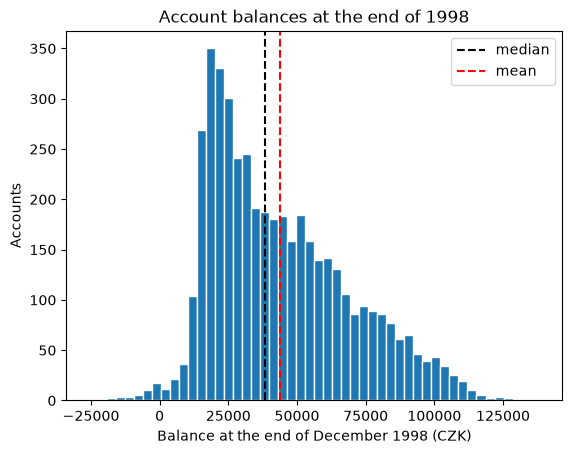

In [42]:
dec_1998 = filled["1998-12"]

print(f"mean balance, Dec 1998:   {dec_1998.mean():>10,.0f} CZK")
print(f"median balance, Dec 1998: {dec_1998.median():>10,.0f} CZK")
print(f"largest balance:          {dec_1998.max():>10,.0f} CZK")

plt.hist(dec_1998, bins=50, edgecolor="white")
plt.axvline(dec_1998.median(), color="black", linestyle="--", label="median")
plt.axvline(dec_1998.mean(), color="red", linestyle="--", label="mean")
plt.xlabel("Balance at the end of December 1998 (CZK)")
plt.ylabel("Accounts")
plt.title("Account balances at the end of 1998")
plt.legend()
plt.show()

The distribution is **right-skewed**: most accounts hold a moderate balance, and a smaller number hold much larger amounts. Those large balances pull the **mean** above the **median**. The median describes a *typical* account better, so I use it, together with the 25th and 75th percentiles to show the spread.

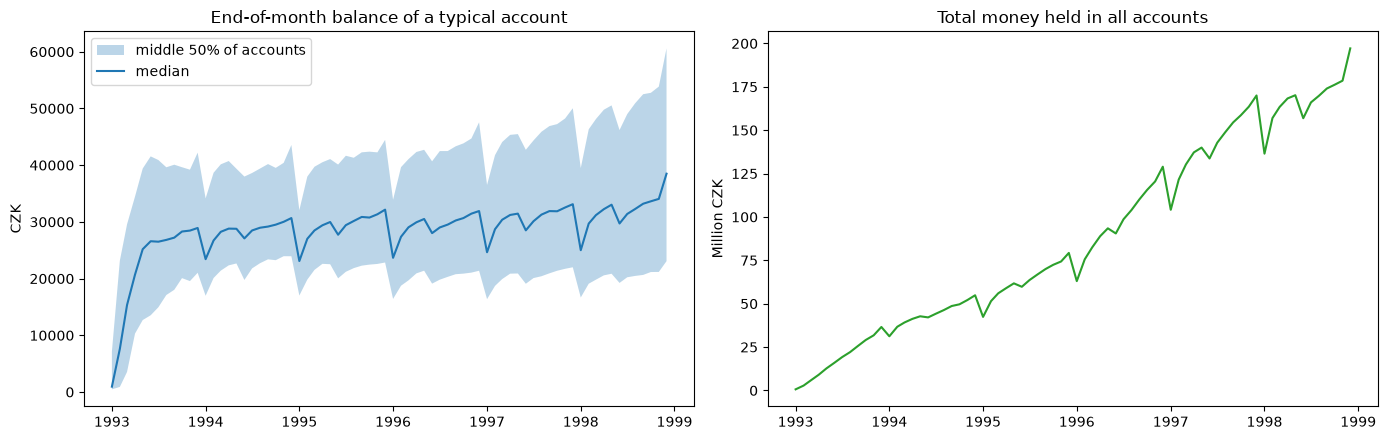

,p25,median,p75,total
month,,,,
1993-12,21022.0,28927.0,42210.0,36575913.0
1994-12,23941.0,30675.0,43552.0,54855812.0
1995-12,22837.0,32155.0,44460.0,79259728.0
1996-12,21383.0,31911.0,47562.0,128950044.0
1997-12,21996.0,33118.0,50034.0,170005463.0
1998-12,23075.0,38495.0,60589.0,197150411.0


In [43]:
balance_over_time = pd.DataFrame({
    "p25": filled.quantile(0.25),
    "median": filled.median(),
    "p75": filled.quantile(0.75),
    "total": filled.sum(),
})
x = balance_over_time.index.to_timestamp()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.fill_between(x, balance_over_time["p25"], balance_over_time["p75"], alpha=0.3, label="middle 50% of accounts")
ax1.plot(x, balance_over_time["median"], label="median")
ax1.set_title("End-of-month balance of a typical account")
ax1.set_ylabel("CZK")
ax1.legend()

ax2.plot(x, balance_over_time["total"] / 1e6, color="tab:green")
ax2.set_title("Total money held in all accounts")
ax2.set_ylabel("Million CZK")

plt.tight_layout()
plt.show()

balance_over_time.loc[["1993-12", "1994-12", "1995-12", "1996-12", "1997-12", "1998-12"]].round(0)

- **1993:** balances start near zero because the accounts are new, but rise quickly. A typical account already holds about **29,000 CZK** by the end of 1993.
- **1994–1997:** the median barely moves, staying between about 30,000 and 33,000 CZK at year end. It then rises to about **38,500 CZK** in December 1998, a large part of that in the final month.
- **Every January, balances drop sharply**, by around 8,000 CZK for a typical account, and then build up again over the year. This matches the January spike in cash withdrawals from the seasonality section. Whatever caused that pattern, the withdrawals really do take money out of the accounts in the data. There is also a smaller dip each June, when withdrawals are larger.
- **The gap between accounts widens.** The 25th percentile stays at about 21,000–24,000 CZK the whole time, but the 75th percentile rises from about 43,500 to 60,600 CZK. Accounts with higher balances kept growing; accounts with lower balances did not.
- The **total** money held rises much faster than the median, because the number of accounts grew. As in Task 2.2, totals mainly reflect growth.
- The histogram shows a small number of accounts **below zero** at the end of 1998. That is the subject of the next section.

`filled` (the balance of every account at the end of every month) will be useful again in step 3, where balance level and stability become customer features.

## Financial stress: negative balances

A negative balance means the customer spent more than they had. For a bank, that is an early sign of **financial stress**, and the bank charges penalty interest for it. I measure how often it happened, using the end-of-day balances.

In [44]:
daily_balance["year"] = daily_balance["date"].dt.year
negative = daily_balance[daily_balance["end_of_day_balance"] < 0]

print(f"account-days with a negative balance: {len(negative):,}")
print(f"accounts that were ever negative:     {negative['account_id'].nunique():,} of {daily_balance['account_id'].nunique():,}")

account-days with a negative balance: 2,046
accounts that were ever negative:     288 of 4,500


As with transactions, the raw count would rise just because the bank grew. So per year I compare the number of accounts that went negative with the number of accounts that were active.

In [45]:
stress = pd.DataFrame({
    "negative_days": negative.groupby("year").size(),
    "accounts_negative": negative.groupby("year")["account_id"].nunique(),
    "active_accounts": daily_balance.groupby("year")["account_id"].nunique(),
})
stress["pct_accounts_negative"] = 100 * stress["accounts_negative"] / stress["active_accounts"]
stress["negative_days_per_account"] = stress["negative_days"] / stress["accounts_negative"]

penalty = trans[trans["purpose"] == "penalty interest"]
stress["penalty_interest_charges"] = penalty.groupby(penalty["date"].dt.year).size()

stress.round(1)

,negative_days,accounts_negative,active_accounts,pct_accounts_negative,negative_days_per_account,penalty_interest_charges
year,,,,,,
1993,11,6,1139,0.5,1.8,9
1994,98,46,1578,2.9,2.1,118
1995,136,54,2239,2.4,2.5,130
1996,175,66,3602,1.8,2.7,188
1997,499,99,4496,2.2,5.0,407
1998,1127,162,4492,3.6,7.0,725


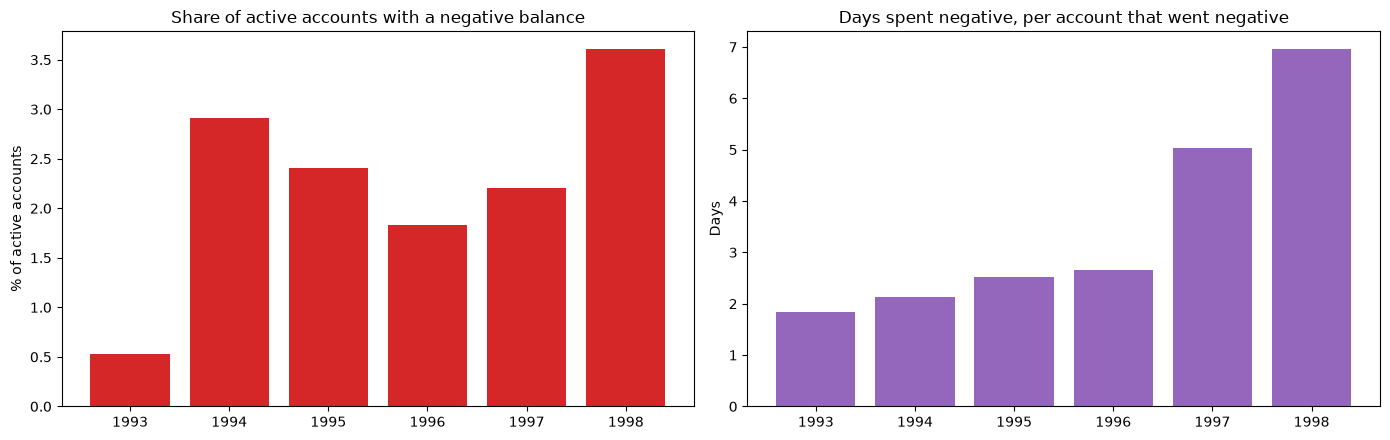

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.bar(stress.index, stress["pct_accounts_negative"], color="tab:red")
ax1.set_title("Share of active accounts with a negative balance")
ax1.set_ylabel("% of active accounts")

ax2.bar(stress.index, stress["negative_days_per_account"], color="tab:purple")
ax2.set_title("Days spent negative, per account that went negative")
ax2.set_ylabel("Days")

plt.tight_layout()
plt.show()

In [47]:
# how deep and how long?
print("How far below zero (CZK):")
print(negative["end_of_day_balance"].describe()[["50%", "min"]].rename({"50%": "median", "min": "deepest"}).round(0))
print()
print("Days negative per account (whole period):")
print(negative.groupby("account_id").size().describe()[["50%", "max"]].rename({"50%": "median"}))

How far below zero (CZK):
median     -2761.0
deepest   -41126.0
Name: end_of_day_balance, dtype: float64

Days negative per account (whole period):
median     3.0
max       79.0
dtype: float64


- Negative balances are **rare but growing**. The share of active accounts that went negative during the year is about 2–3% from 1994 to 1997, then rises to **3.6% in 1998**.
- They also last longer: accounts that went negative spent about 2–3 days below zero in 1993–1996, then 5 days in 1997 and **7 days in 1998**. Penalty interest charges rise in the same way.
- Most episodes are short and shallow: the typical negative balance is about −2,800 CZK, and a typical affected account spends only a few days below zero over the whole six years. A few accounts are much worse, down to about −41,000 CZK or almost 80 days.

So financial stress increased towards the end of the period, both in how many customers were affected and in how long it lasted.

### A first look at the link to loans

The credit-risk part (step 4) asks which customers default on loans. Negative balances are an obvious candidate signal, so here is a first look: of the accounts with a good loan, a bad loan or no loan, how many were ever negative?

In [48]:
ever_negative = set(negative["account_id"])
account_profile["ever_negative"] = account_profile["account_id"].isin(ever_negative)

loan_group = account_profile["loan_is_bad"].map({True: "bad loan", False: "good loan"}).fillna("no loan")
pd.crosstab(account_profile["ever_negative"], loan_group)

loan_is_bad,bad loan,good loan,no loan
ever_negative,,,
False,0,606,3606
True,76,0,212


This is a remarkably clean split: **every one of the 76 accounts with a bad loan** went negative at some point, and **none of the 606 accounts with a good loan** ever did.

That looks like a perfect predictor, which should make me suspicious rather than excited. The important question is **timing**: a bank deciding whether to grant a loan only knows what happened *before* the loan. If the balances only went negative *after* the loan, because the customer was already struggling to repay, then this is a **consequence** of the bad loan, not a warning sign. Using it would be **data leakage**: the model would be "predicting" with information from the future.

In [49]:
loans = pd.read_parquet("data/clean/loan.parquet")
first_negative = negative.groupby("account_id")["date"].min().rename("first_negative")

timing = loans.set_index("account_id").join(first_negative)
timing["when"] = "never negative"
timing.loc[timing["first_negative"] < timing["date"], "when"] = "negative before the loan"
timing.loc[timing["first_negative"] >= timing["date"], "when"] = "first negative after the loan"

pd.crosstab(timing["when"], timing["is_bad"].map({True: "bad loan", False: "good loan"}))

is_bad,bad loan,good loan
when,,
first negative after the loan,49,0
negative before the loan,27,0
never negative,0,606


- For **49 of the 76 bad loans**, the account first went negative only **after** the loan was granted. That information wasn't available when the loan was approved, so it **can't** be used to predict default.
- But **27 bad loans** had already gone negative **before** the loan, compared with **0 of the 606 good loans**. That is a genuine early warning sign that the bank could have seen at the time of the decision.

A rule like *"never give a loan to an account that has been negative"* would have caught about a third of the bad loans and refused no good ones. That is a strong lead for step 4, with two cautions:
- It is still too clean for real-world data (another sign the dataset may have been partly generated), so I will test it properly with cross-validation rather than trust it.
- In step 4, every feature must be calculated **only from data before the loan date**, for exactly the reason shown here.

## Changing habits: cash, transfers and cards

Finally, *how* customers used the bank: did they move from cash towards transfers and cards? I compare the share of each type of transaction per year. January is left out again, so the January cash and card withdrawals (the likely artifact) don't distort the mix.

In [50]:
habits = customer_trans[customer_trans["date"].dt.month != 1].copy()
habits["year"] = habits["date"].dt.year

share_by_count = pd.crosstab(habits["year"], habits["operation"], normalize="index") * 100
share_by_amount = pd.crosstab(habits["year"], habits["operation"], values=habits["amount"],
                              aggfunc="sum", normalize="index") * 100

print("Share of transactions (%)")
print(share_by_count.round(1))
print()
print("Share of money moved (%)")
print(share_by_amount.round(1))

Share of transactions (%)
operation  card withdrawal  cash deposit  cash withdrawal  transfer in  \
year                                                                     
1993                   0.0          34.4             35.8         12.8   
1994                   0.1          23.2             37.3         10.0   
1995                   0.3          23.2             35.9          9.8   
1996                   0.5          24.2             35.6          9.8   
1997                   0.8          23.1             34.9          9.6   
1998                   1.5          22.1             32.7          9.5   

operation  transfer out  
year                     
1993               16.9  
1994               29.4  
1995               30.8  
1996               29.9  
1997               31.6  
1998               34.2  

Share of money moved (%)
operation  card withdrawal  cash deposit  cash withdrawal  transfer in  \
year                                                                     

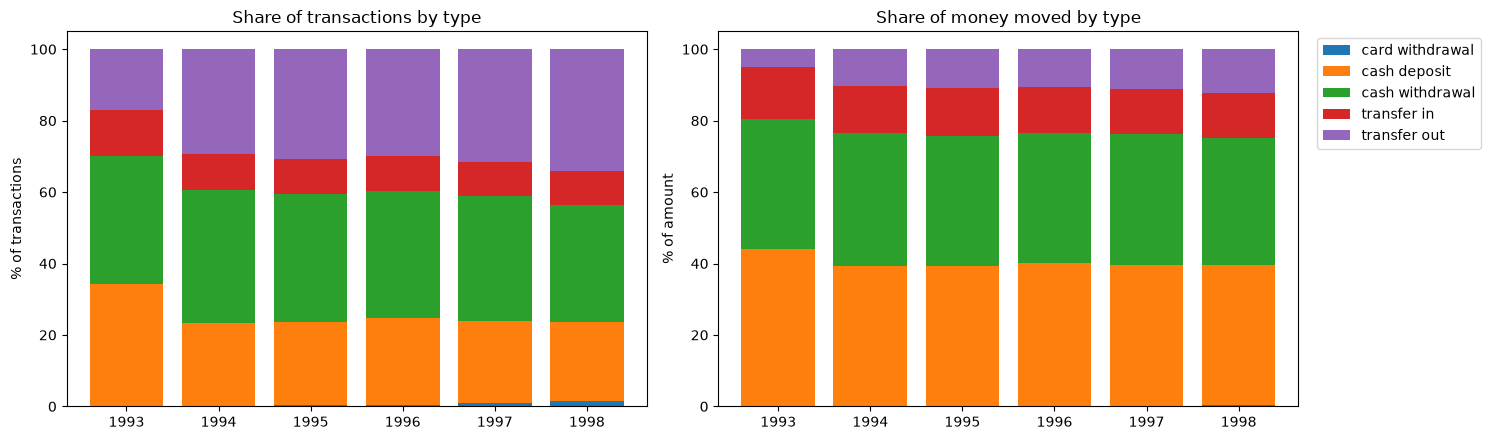

In [51]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

share_by_count.plot(kind="bar", stacked=True, ax=ax1, width=0.8, legend=False, rot=0)
ax1.set_title("Share of transactions by type")
ax1.set_ylabel("% of transactions")
ax1.set_xlabel("")

share_by_amount.plot(kind="bar", stacked=True, ax=ax2, width=0.8, rot=0)
ax2.set_title("Share of money moved by type")
ax2.set_ylabel("% of amount")
ax2.set_xlabel("")
ax2.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Cards

Card withdrawals are still a small share, but the cards themselves were new. When were they issued, and how much were they used?

In [52]:
cards = pd.read_parquet("data/clean/card.parquet")
card_use = habits[habits["operation"] == "card withdrawal"]

card_growth = pd.DataFrame({
    "cards_issued": cards.groupby(cards["issued"].dt.year).size(),
    "card_withdrawals": card_use.groupby("year").size(),
}).fillna(0).astype(int)
card_growth["cards_in_use"] = card_growth["cards_issued"].cumsum()
card_growth["withdrawals_per_card"] = (card_growth["card_withdrawals"] / card_growth["cards_in_use"]).round(1)
card_growth

,cards_issued,card_withdrawals,cards_in_use,withdrawals_per_card
1993,1,0,1,0.0
1994,21,56,22,2.5
1995,63,218,85,2.6
1996,116,577,201,2.9
1997,242,1362,443,3.1
1998,449,2858,892,3.2


- **Transfers out** (household bills, insurance, loan repayments and other payments) grew from about **17% of transactions in 1993 to 34% in 1998**. Most of the jump came in 1994, as new customers set up their regular payments; after that it grew slowly but steadily. These are many small payments: transfers out are a third of all transactions but only about 11–12% of the money moved.
- **Cash deposits** fell from 34% to about 23% after the first year, then stayed there. The high 1993 share is the start-up effect: new accounts begin with a deposit.
- **Cash withdrawals** remain the most common transaction every year, and **cash deposits** move the most money. This was still mainly a cash bank.
- **Cards** arrived late: half of all cards were issued in 1998 alone, and card withdrawals grew fast but from almost nothing (1.5% of transactions in 1998). Each card was used only a few times a year outside January.

So customers did shift slowly from cash to transfers, and cards were only starting to be used when the data ends. For segmentation, **how much a customer relies on cash versus transfers** is likely to differ between customers, so it is a good candidate feature.


## Summary of step 2

### Key findings

1. **The bank grew from 96 to about 4,500 active accounts between 1993 and 1997**, but individual customers hardly changed. A typical account made about 3.5–4 transactions a month in every year, with an average transaction of about 9,000 CZK. Almost all the growth in activity and money came from more customers, not from customers doing more.

2. **Balances grew slowly, and unevenly.** A typical account held about 30,000–33,000 CZK at the end of each year from 1994 to 1997, rising to about 38,500 CZK at the end of 1998. Accounts with higher balances grew much faster than those with lower balances, so the gap between customers widened.

3. **Financial stress increased at the end of the period.** The share of accounts going into a negative balance rose to 3.6% in 1998, and those accounts stayed negative longer (7 days on average, up from 2–3). Penalty interest charges grew sixfold between 1994 and 1998.

4. **Negative balances are closely linked to bad loans.** Every account with a bad loan went negative at some point, and no account with a good loan did. Most of that happened after the loan was granted (a consequence, not a warning), but 27 bad-loan accounts were already negative before the loan, against none of the good ones.

5. **Customers slowly moved from cash towards transfers,** which doubled from 17% to 34% of transactions. It was still mainly a cash bank, and cards had only just started to be used by 1998.

### Data quirks found

- **January:** cash and card withdrawals jump to about 4–8 times their normal level every year, in a way that looks rule-generated rather than real.
- **Days 5–14:** every transfer in the data happens between the 5th and 14th of the month, and every loan repayment on the 12th.

### Decisions for the next steps

- **Segmentation (step 3):** leave out January when building customer features, don't use timing within the month, and use the **median** rather than the mean for typical values. Promising features: balance level and stability, activity per month, and the share of cash versus transfers.
- **Credit risk (step 4):** calculate every feature **only from data before the loan date**, to avoid leakage. A negative balance before the loan is the first candidate signal to test.
